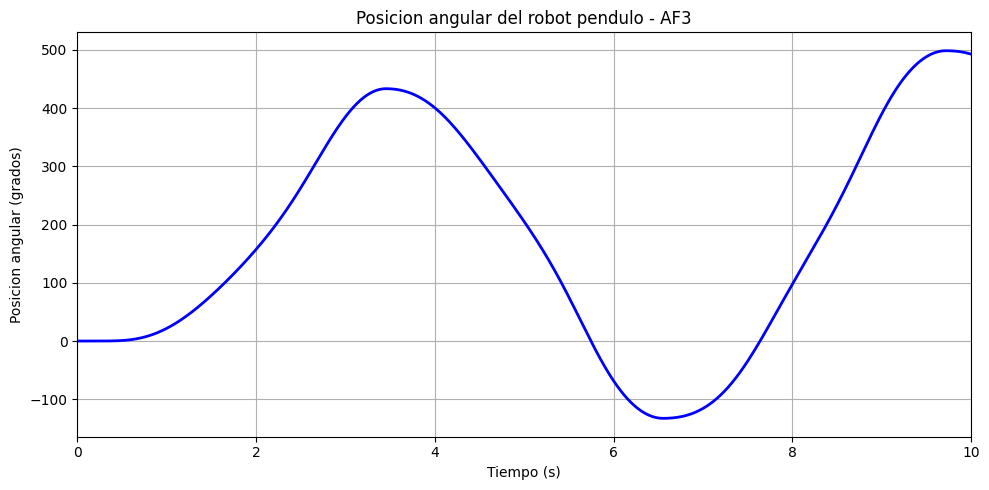

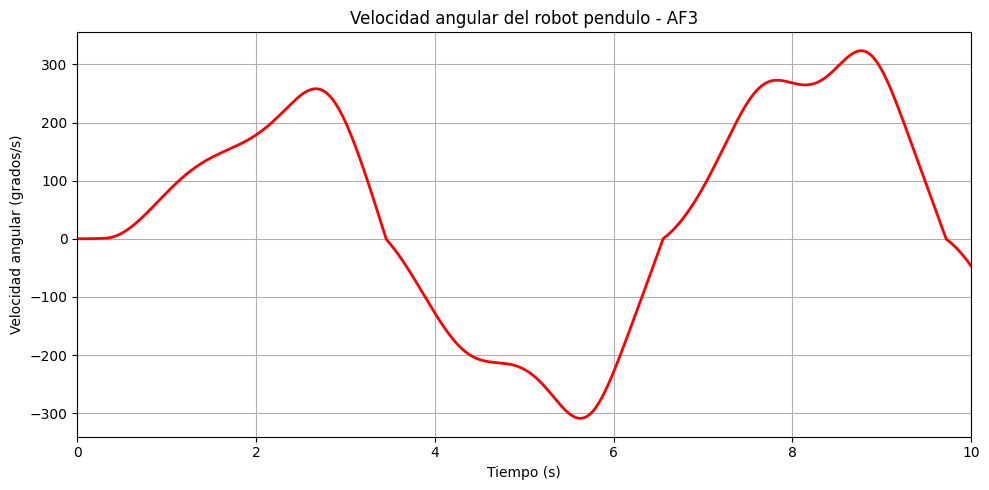

       RESULTADOS DE LA AF3

PARAMETROS DEL SISTEMA:
Momento de inercia: 0.16
Masa: 5.0
Gravedad: 9.81
Distancia al centro de masa: 0.01
Viscosidad: 0.14
Friccion: 0.45

CONDICIONES INICIALES:
X1 = 0
X2 = 0

RESULTADOS FINALES:
Tiempo de simulacion: 10 segundos
Posicion final: 492.68089334913856 grados
Velocidad final: -46.99139655589676 grados/s


In [1]:

# ============================================================
# INTEGRANTES DEL EQUIPO
# ============================================================
# Juan Carlos Castillo Guerra       2144789
# Perla Ximena Álvarez Silerio      2142704
# Arturo Rosales Ponce              2142669
# Samantha Nohemi Moreno Treviño    2154902

# ============================================================
# AF 3 - SIMULACION NUMERICA E INTERPRETACION DINAMICA
# ROBOT PENDULO DE 1 GRADO DE LIBERTAD
# MODELO OBTENIDO MEDIANTE EULER-LAGRANGE
# ============================================================

import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. PARAMETROS DEL SISTEMA
# ------------------------------------------------------------

Ir = 0.16       # Momento de inercia
m = 5.0         # Masa del mecanismo (kg)
g = 9.81        # Gravedad (m/s^2)
lc = 0.01       # Distancia al centro de masa (m)
b = 0.14        # Coeficiente de viscosidad
fc = 0.45       # Coeficiente de friccion

# ------------------------------------------------------------
# 2. TORQUE DEL MOTOR
# ------------------------------------------------------------

def tau(t):
    return 1.5 * np.sin(t)

# ------------------------------------------------------------
# 3. MODELO DINAMICO - EULER-LAGRANGE
# ------------------------------------------------------------

def f(t, x):

    # Variables de estado
    x1 = x[0]    # Posicion angular
    x2 = x[1]    # Velocidad angular

    # Torque aplicado
    Tm = tau(t)

    # Friccion de Coulomb
    friccion = fc * np.tanh(100 * x2)

    # Ecuacion dinamica
    x2p = (Tm - b*x2 - friccion
           - m*g*lc*np.sin(x1)) / Ir

    # Espacio de estados
    x1p = x2

    return [x1p, x2p]

# ------------------------------------------------------------
# 4. CONDICIONES INICIALES
# ------------------------------------------------------------

ti = 0
tf = 10

X1 = 0
X2 = 0

x0 = [X1, X2]

# Tiempo de simulacion
ts = np.linspace(ti, tf, 2000)

# ------------------------------------------------------------
# 5. SIMULACION NUMERICA
# ------------------------------------------------------------

sol = solve_ivp(
    f,
    [ti, tf],
    x0,
    t_eval=ts,
    method='RK45',
    rtol=1e-7,
    atol=1e-9
)

# Extraer resultados
t = sol.t
posicion = sol.y[0]
velocidad = sol.y[1]

# Conversion de radianes a grados
posicion_grados = np.rad2deg(posicion)
velocidad_grados = np.rad2deg(velocidad)

# ------------------------------------------------------------
# 6. GRAFICA DE POSICION ANGULAR
# ------------------------------------------------------------

plt.figure(figsize=(10,5))

plt.plot(t, posicion_grados, 'b', linewidth=2)

plt.title('Posicion angular del robot pendulo - AF3')
plt.xlabel('Tiempo (s)')
plt.ylabel('Posicion angular (grados)')
plt.grid(True)
plt.xlim(0,10)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. GRAFICA DE VELOCIDAD ANGULAR
# ------------------------------------------------------------

plt.figure(figsize=(10,5))

plt.plot(t, velocidad_grados, 'r', linewidth=2)

plt.title('Velocidad angular del robot pendulo - AF3')
plt.xlabel('Tiempo (s)')
plt.ylabel('Velocidad angular (grados/s)')
plt.grid(True)
plt.xlim(0,10)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. RESULTADOS DE LA SIMULACION
# ------------------------------------------------------------

print("======================================")
print("       RESULTADOS DE LA AF3")
print("======================================")

print("\nPARAMETROS DEL SISTEMA:")
print("Momento de inercia:", Ir)
print("Masa:", m)
print("Gravedad:", g)
print("Distancia al centro de masa:", lc)
print("Viscosidad:", b)
print("Friccion:", fc)

print("\nCONDICIONES INICIALES:")
print("X1 =", X1)
print("X2 =", X2)

print("\nRESULTADOS FINALES:")
print("Tiempo de simulacion:", tf, "segundos")
print("Posicion final:", posicion_grados[-1], "grados")
print("Velocidad final:", velocidad_grados[-1], "grados/s")

print("======================================")
